# Práctica 1 – Ingeniería del Conocimiento: Fase 4: Ajuste de hiperparámetros y predicción final

Este cuaderno continúa la Fase 3. Se ajustan los dos finalistas de la Fase 3 (Ridge sobre log(precio) con splines y GradientBoosting sobre log(precio)), se prueba su mezcla, se confirma lo elegido con una CV de control y se genera el fichero de entrega.

| Apartado de la memoria | Sección del cuaderno |
|---|---|
| 4.1 Ajuste del modelo lineal (nodos de las splines y alpha) | F4.1 |
| 4.2 Ajuste de GradientBoosting (búsqueda aleatoria) | F4.2 |
| 4.3 Mezcla de los dos modelos | F4.3 |
| 4.4 Modelo final y CV de control | F4.4 |
| 4.5 Predicción del test y fichero de entrega | F4.5 |

In [1]:
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold, KFold, ParameterSampler

SEED = 42

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | scipy 1.16.3 | matplotlib 3.10.0


## 0 Carga de datos
Se leen `train-1.csv` y `test-1.csv` de la misma carpeta que el cuaderno.

In [2]:
RUTA_DATOS = ''   # carpeta de los CSV; '' = misma carpeta que el cuaderno
tr = pd.read_csv(RUTA_DATOS + 'train-1.csv')
te = pd.read_csv(RUTA_DATOS + 'test-1.csv')

X = tr.drop(columns=['id', 'price']).copy()
y = tr['price'].to_numpy(dtype=float)
X_test = te.drop(columns=['id']).copy()
print('X:', X.shape, '| X_test:', X_test.shape)

X: (8000, 14) | X_test: (2000, 14)


## Definiciones (las mismas que en la Fase 3)

In [3]:
UMBRAL = 300   # tramo de precio para el desglose del error: <= 300 € y > 300 €

# Preprocesado decidido en la Fase 2: fuera material, brand_tier, is_promo y country
CAT_SEL = ['category', 'brand', 'season', 'channel']
NUMS = ['peso', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount']


def variables(df, peso='crudo', log_reviews=False):
    """Variables del modelo. Las transformaciones son fila a fila (no aprenden nada de los datos),
    así que se pueden calcular antes de la CV sin fuga de información.
    peso: 'crudo' (weight_kg), 'log' (log(weight_kg)) o 'log1p' (log(1 + weight_kg))."""
    out = df[CAT_SEL].astype(str).copy()
    out['peso'] = {'crudo': df.weight_kg, 'log': np.log(df.weight_kg), 'log1p': np.log1p(df.weight_kg)}[peso]
    out['rating'] = df.rating
    out['reviews'] = np.log1p(df.reviews) if log_reviews else df.reviews
    out['shipping_cost'] = df.shipping_cost
    out['margin'] = df.margin
    out['discount'] = df.discount
    return out


def lineal(splines=False, n_knots=5, alpha=None):
    """Modelo lineal: one-hot (drop='first') + numéricas estandarizadas [+ splines cúbicas de las numéricas].
    Con splines se usa Ridge, porque las splines y los términos lineales son colineales."""
    tf = [('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT_SEL),
          ('num', StandardScaler(), NUMS)]
    if splines:
        tf.append(('spl', SplineTransformer(n_knots=n_knots, degree=3), NUMS))
    reg = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return Pipeline([('prep', ColumnTransformer(tf)), ('model', reg)])


def arboles(modelo, **params):
    """Modelos de árboles: one-hot sin drop + numéricas sin escalar."""
    prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_SEL),
                              ('num', 'passthrough', NUMS)])
    est = {'hgb': HistGradientBoostingRegressor, 'rf': RandomForestRegressor,
           'gbr': GradientBoostingRegressor}[modelo](random_state=SEED, **params)
    return Pipeline([('prep', prep), ('model', est)])


class LogDuan(RegressorMixin, BaseEstimator):
    """Entrena sobre log(price) y devuelve euros: factor * exp(pred), con el factor de Duan
    (media de exp(residuo en log)). residuals='oof': residuos fuera de muestra con una CV interna de
    n_inner folds (solo datos de entrenamiento) | 'insample': residuos del propio ajuste (más rápido)."""
    def __init__(self, estimator, residuals='oof', n_inner=5, seed=42):
        self.estimator = estimator
        self.residuals = residuals
        self.n_inner = n_inner
        self.seed = seed

    def fit(self, X, y):
        ylog = np.log(np.asarray(y, dtype=float))
        self.est_ = clone(self.estimator).fit(X, ylog)
        if self.residuals == 'insample':
            r = ylog - self.est_.predict(X)
        else:
            oof = np.zeros_like(ylog)
            for a, b in KFold(self.n_inner, shuffle=True, random_state=self.seed).split(X):
                oof[b] = clone(self.estimator).fit(X.iloc[a], ylog[a]).predict(X.iloc[b])
            r = ylog - oof
        self.factor_ = float(np.mean(np.exp(r)))
        return self

    def predict(self, X):
        return self.factor_ * np.exp(self.est_.predict(X))


class Mezcla(RegressorMixin, BaseEstimator):
    """Media ponderada de dos modelos: w * A + (1 - w) * B."""
    def __init__(self, a, b, w=0.5):
        self.a = a
        self.b = b
        self.w = w

    def fit(self, X, y):
        self.a_ = clone(self.a).fit(X, y)
        self.b_ = clone(self.b).fit(X, y)
        return self

    def predict(self, X):
        return self.w * self.a_.predict(X) + (1 - self.w) * self.b_.predict(X)


RES = {}   # métricas por fold de cada variante
OOF = {}   # predicciones fuera de muestra (una fila por repetición) para poder mezclar modelos


def evaluar(nombre, est, Xf, splits):
    """CV con las particiones dadas. Todas las métricas en euros (escala original)."""
    t0 = time.time()
    filas = []
    pred = np.full((len(splits) // 5, len(y)), np.nan)
    for k, (a, b) in enumerate(splits):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            m = clone(est).fit(Xf.iloc[a], y[a])
            p = m.predict(Xf.iloc[b])
        pred[k // 5, b] = p
        yt = y[b]
        e = p - yt
        sse = float(np.sum(e ** 2))
        lo = yt <= UMBRAL
        hi = ~lo
        filas.append(dict(fold=k,
                          rmse=np.sqrt(sse / len(yt)),
                          mae=float(np.mean(np.abs(e))),
                          r2=1 - sse / float(np.sum((yt - yt.mean()) ** 2)),
                          rmse_le300=np.sqrt(np.mean(e[lo] ** 2)),
                          rmse_gt300=np.sqrt(np.mean(e[hi] ** 2)) if hi.any() else np.nan,
                          share_gt300=float(np.sum(e[hi] ** 2)) / sse))
    df = pd.DataFrame(filas)
    df.attrs['seg'] = time.time() - t0
    RES[nombre] = df
    OOF[nombre] = pred
    print(f'  {nombre}: RMSE {df.rmse.mean():.3f} ({df.attrs["seg"]:.0f} s)')
    return df


def resumen(nombres, ref):
    """Igual que en la Fase 2: media y desviación del RMSE (15 folds), diferencia emparejada frente a `ref`,
    RMSE por tramo, % del error cuadrático del tramo > 300 €, MAE y R².
    Una MEJORA solo cuenta si |media de la diferencia| > su desviación entre folds."""
    filas = []
    r = RES[ref].rmse.to_numpy()
    for n in nombres:
        d = RES[n]
        dif = d.rmse.to_numpy() - r
        m, s = dif.mean(), dif.std(ddof=1)
        if n == ref:
            ver = '(referencia)'
        elif abs(m) < 1e-6:
            ver = 'IDÉNTICO'
        elif m < 0 and abs(m) > s:
            ver = 'MEJORA'
        elif (m > 0 and m > s) or (dif >= 0).all():
            ver = 'EMPEORA'
        else:
            ver = 'EMPATE'
        filas.append(dict(variante=n, RMSE=d.rmse.mean(), std=d.rmse.std(ddof=1), dif_media=m, dif_std=s,
                          folds_mejor=int((dif < 0).sum()), RMSE_le300=d.rmse_le300.mean(),
                          RMSE_gt300=d.rmse_gt300.mean(), pct_MSE_gt300=100 * d.share_gt300.mean(),
                          MAE=d.mae.mean(), R2=d.r2.mean(), veredicto=ver))
    return pd.DataFrame(filas).set_index('variante')


def mostrar(df):
    print(df.round({'RMSE': 3, 'std': 3, 'dif_media': 3, 'dif_std': 3, 'RMSE_le300': 3, 'RMSE_gt300': 3,
                    'pct_MSE_gt300': 1, 'MAE': 3, 'R2': 4}).to_string())


def firma(splits):
    """Huella de las particiones (para comprobar que son las mismas que en la Fase 2)."""
    return hashlib.md5(np.concatenate([b for _, b in splits]).astype(np.int64).tobytes()).hexdigest()[:12]


# Particiones congeladas en la Fase 2 (KFold aleatorio 5x3, semilla 42)
SPLITS = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X))
assert firma(SPLITS) == '0589e8baabcf', 'Las particiones no coinciden con las de la Fase 2'
print('Particiones congeladas OK, huella', firma(SPLITS))

# Conjunto de variables final (justificado en la Fase 3)
XF = variables(X, peso='log1p', log_reviews=True)
XF_test = variables(X_test, peso='log1p', log_reviews=True)

Particiones congeladas OK, huella 0589e8baabcf


## F4.1 Ajuste del modelo lineal: nodos de las splines y alpha de Ridge
Rejilla completa de 4 × 5 = 20 combinaciones, cada una con los 15 folds congelados y Duan OOF. Es rápido porque el modelo es lineal.

In [4]:
t_ini = time.time()
REF = 'LIN|ref Fase 2 (euros)'
evaluar(REF, lineal(), variables(X, peso='crudo'), SPLITS)
evaluar('RIDGE|nodos=5 alpha=1 (Fase 3)', LogDuan(lineal(splines=True, n_knots=5, alpha=1.0)), XF, SPLITS)

rej = []
for nk in [4, 5, 6, 8]:
    for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
        n = f'RIDGE|nodos={nk} alpha={alpha:g}'
        if n not in RES:
            evaluar(n, LogDuan(lineal(splines=True, n_knots=nk, alpha=alpha)), XF, SPLITS)
        rej.append(dict(nodos=nk, alpha=alpha, RMSE=RES[n].rmse.mean()))
rej = pd.DataFrame(rej)
print('\nRMSE medio (15 folds) por combinación:')
print(rej.pivot(index='nodos', columns='alpha', values='RMSE').round(3).to_string())

mejor = rej.loc[rej.RMSE.idxmin()]
BEST_LIN = f'RIDGE|nodos={int(mejor.nodos)} alpha={mejor.alpha:g}'
PARAMS_LIN = dict(n_knots=int(mejor.nodos), alpha=float(mejor.alpha))
print(f'\nMejor combinación: {BEST_LIN}')
mostrar(resumen([REF, 'RIDGE|nodos=5 alpha=1 (Fase 3)', BEST_LIN], REF))
print(f'\nTiempo: {time.time() - t_ini:.0f} s')

  LIN|ref Fase 2 (euros): RMSE 54.054 (0 s)


  RIDGE|nodos=5 alpha=1 (Fase 3): RMSE 52.383 (2 s)


  RIDGE|nodos=4 alpha=0.01: RMSE 52.441 (2 s)


  RIDGE|nodos=4 alpha=0.1: RMSE 52.429 (2 s)


  RIDGE|nodos=4 alpha=1: RMSE 52.469 (2 s)


  RIDGE|nodos=4 alpha=10: RMSE 52.501 (2 s)


... (12 outputs left out)

  RIDGE|nodos=8 alpha=0.1: RMSE 52.407 (3 s)


  RIDGE|nodos=8 alpha=1: RMSE 52.402 (2 s)


  RIDGE|nodos=8 alpha=10: RMSE 52.416 (2 s)


  RIDGE|nodos=8 alpha=100: RMSE 52.619 (3 s)

RMSE medio (15 folds) por combinación:
alpha  0.01    0.10    1.00    10.00   100.00
nodos                                        
4      52.441  52.429  52.469  52.501  52.617
5      52.374  52.386  52.383  52.416  52.629
6      52.503  52.481  52.439  52.428  52.631
8      52.442  52.407  52.402  52.416  52.619

Mejor combinación: RIDGE|nodos=5 alpha=0.01
                                  RMSE    std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                           
LIN|ref Fase 2 (euros)          54.054  5.046      0.000    0.000            0      38.744     173.603           50.0  34.784  0.5257  (referencia)
RIDGE|nodos=5 alpha=1 (Fase 3)  52.383  4.875     -1.671    0.752           15      38.390     164.434           47.7  33.354  0.5544        MEJORA
RI

## F4.2 Ajuste de GradientBoosting: búsqueda aleatoria
GradientBoosting es mucho más lento que el lineal, así que se hace en dos etapas:
1. **Búsqueda:** 15 combinaciones aleatorias evaluadas en la primera repetición (5 folds) con Duan sobre residuos de entrenamiento, que es más rápido. Solo sirve para ordenar las combinaciones.
2. **Confirmación:** las 2 mejores se evalúan con los 15 folds y Duan OOF, igual que el resto de modelos.

`n_estimators` es alto y se usa parada temprana (`n_iter_no_change`), así que el número de árboles lo decide el propio modelo.

In [5]:
t_ini = time.time()
ESPACIO = {'learning_rate': [0.05, 0.1],
           'max_depth': [1, 2, 3, 4],
           'min_samples_leaf': [5, 20, 50, 100],
           'subsample': [0.7, 1.0],
           'max_features': [None, 0.5]}
COMUNES = dict(n_estimators=1500, validation_fraction=0.1, n_iter_no_change=30, tol=1e-5)

busq = []
for i, p in enumerate(ParameterSampler(ESPACIO, n_iter=15, random_state=SEED)):
    rmse = []
    for a, b in SPLITS[:5]:
        m = LogDuan(arboles('gbr', **p, **COMUNES), residuals='insample').fit(XF.iloc[a], y[a])
        rmse.append(np.sqrt(np.mean((m.predict(XF.iloc[b]) - y[b]) ** 2)))
    busq.append(dict(**p, RMSE_5folds=np.mean(rmse)))
    print(f'  combinación {i + 1}/15: {np.mean(rmse):.3f}')
busq = pd.DataFrame(busq).sort_values('RMSE_5folds')
print('\nBúsqueda (primera repetición, 5 folds), 10 mejores:')
print(busq.head(10).to_string(index=False))
print(f'[búsqueda: {time.time() - t_ini:.0f} s]')

print('\nConfirmación de las 2 mejores con los 15 folds y Duan OOF:')
evaluar('GBR|log + Duan (por defecto)', LogDuan(arboles('gbr')), XF, SPLITS)
top = []
for _, fila in busq.head(2).iterrows():
    p = dict(learning_rate=float(fila.learning_rate), max_depth=int(fila.max_depth),
             min_samples_leaf=int(fila.min_samples_leaf), subsample=float(fila.subsample),
             max_features=None if pd.isna(fila.max_features) else float(fila.max_features))
    n = 'GBR|' + ' '.join(f'{k}={v}' for k, v in p.items())
    evaluar(n, LogDuan(arboles('gbr', **p, **COMUNES)), XF, SPLITS)
    top.append((n, p))
BEST_ARB, PARAMS_ARB = min(top, key=lambda t: RES[t[0]].rmse.mean())
mostrar(resumen([REF, 'GBR|log + Duan (por defecto)'] + [n for n, _ in top], REF))
print(f'\nMejor GradientBoosting: {BEST_ARB}')
print(f'Tiempo: {time.time() - t_ini:.0f} s')

  combinación 1/15: 53.877


  combinación 2/15: 53.090


  combinación 3/15: 52.907


  combinación 4/15: 53.363


  combinación 5/15: 53.120


  combinación 6/15: 53.274


... (8 outputs left out)

  combinación 15/15: 53.255

Búsqueda (primera repetición, 5 folds), 10 mejores:
 subsample  min_samples_leaf  max_features  max_depth  learning_rate  RMSE_5folds
       0.7                20           0.5          2           0.05    52.692119
       0.7                 5           NaN          1           0.10    52.757169
       1.0                50           NaN          1           0.10    52.770067
       1.0                20           NaN          2           0.05    52.906795
       1.0                20           0.5          2           0.05    52.924784
       0.7                50           NaN          1           0.05    52.947487
       0.7                 5           0.5          3           0.05    53.089782
       1.0                 5           NaN          2           0.10    53.101139
       0.7                20           NaN          3           0.10    53.119874
       0.7                 5           NaN          3           0.10    53.254512
[búsqueda: 136 s]

  GBR|log + Duan (por defecto): RMSE 53.765 (78 s)


  GBR|learning_rate=0.05 max_depth=2 min_samples_leaf=20 subsample=0.7 max_features=0.5: RMSE 52.820 (104 s)


  GBR|learning_rate=0.1 max_depth=1 min_samples_leaf=5 subsample=0.7 max_features=None: RMSE 52.779 (101 s)
                                                                                         RMSE    std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                                                                                  
LIN|ref Fase 2 (euros)                                                                 54.054  5.046      0.000    0.000            0      38.744     173.603           50.0  34.784  0.5257  (referencia)
GBR|log + Duan (por defecto)                                                           53.765  4.908     -0.289    0.840           11      38.716     171.921           49.5  34.374  0.5308        EMPATE
GBR|learning_rate=0.05 max_depth=2 min_samples_leaf=20 subsample=0.7 max_feature

## F4.3 Mezcla de los dos modelos
Se combinan las predicciones fuera de muestra ya calculadas: w · Ridge + (1 − w) · GradientBoosting, con w de 0 a 1. Como el peso w se elige mirando estos mismos folds, la mezcla solo se adopta si **mejora** al mejor modelo individual según el criterio de siempre; si empata, se queda el modelo individual, que es más simple.

In [6]:
def rmse_folds(pred, splits=SPLITS):
    return np.array([np.sqrt(np.mean((pred[k // 5, b] - y[b]) ** 2)) for k, (_, b) in enumerate(splits)])

base_ind = BEST_LIN if RES[BEST_LIN].rmse.mean() <= RES[BEST_ARB].rmse.mean() else BEST_ARB
r_base = RES[base_ind].rmse.to_numpy()
filas = []
for w in np.round(np.arange(0, 1.01, 0.1), 1):
    r = rmse_folds(w * OOF[BEST_LIN] + (1 - w) * OOF[BEST_ARB])
    dif = r - r_base
    filas.append(dict(w_ridge=w, RMSE=r.mean(), std=r.std(ddof=1), dif_media=dif.mean(), dif_std=dif.std(ddof=1),
                      folds_mejor=int((dif < 0).sum())))
mez = pd.DataFrame(filas).set_index('w_ridge')
print(f'Mezcla w · {BEST_LIN} + (1 - w) · {BEST_ARB}  (diferencias frente a {base_ind})')
print(mez.round(3).to_string())

w_opt = float(mez.RMSE.idxmin())
fila = mez.loc[w_opt]
usar_mezcla = (0 < w_opt < 1) and (fila.dif_media < 0) and (abs(fila.dif_media) > fila.dif_std)
print(f'\nMejor w = {w_opt:g}: dif {fila.dif_media:+.3f} ± {fila.dif_std:.3f} ->',
      'MEJORA, se usa la mezcla' if usar_mezcla else f'no supera el criterio, se queda {base_ind}')

Mezcla w · RIDGE|nodos=5 alpha=0.01 + (1 - w) · GBR|learning_rate=0.1 max_depth=1 min_samples_leaf=5 subsample=0.7 max_features=None  (diferencias frente a RIDGE|nodos=5 alpha=0.01)
           RMSE    std  dif_media  dif_std  folds_mejor
w_ridge                                                
0.0      52.779  4.933      0.405    0.374            1
0.1      52.698  4.932      0.323    0.331            2
0.2      52.625  4.931      0.251    0.289            4
0.3      52.562  4.930      0.188    0.249            5
0.4      52.508  4.929      0.133    0.210            5
0.5      52.462  4.927      0.088    0.172            5
0.6      52.426  4.925      0.052    0.135            5
0.7      52.400  4.923      0.025    0.100            5
0.8      52.382  4.920      0.008    0.066            6
0.9      52.374  4.917     -0.001    0.032            8
1.0      52.374  4.913      0.000    0.000            0

Mejor w = 0.9: dif -0.001 ± 0.032 -> no supera el criterio, se queda RIDGE|nodos=5 alpha=

## F4.4 Modelo final y CV de control
Se fija el modelo final y se comprueba con otra semilla de CV (2026), que no se ha usado para elegir nada, que la mejora frente a la referencia de la Fase 2 no depende de las particiones.

In [7]:
EST_LIN = LogDuan(lineal(splines=True, **PARAMS_LIN))
EST_ARB = LogDuan(arboles('gbr', **PARAMS_ARB, **COMUNES))
if usar_mezcla:
    FINAL, NOMBRE_FINAL = Mezcla(EST_LIN, EST_ARB, w=w_opt), f'MEZCLA w={w_opt:g}'
elif base_ind == BEST_LIN:
    FINAL, NOMBRE_FINAL = EST_LIN, BEST_LIN
else:
    FINAL, NOMBRE_FINAL = EST_ARB, BEST_ARB
print('MODELO FINAL:', NOMBRE_FINAL)
print(FINAL)

SPLITS_CTRL = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=2026).split(X))
print(f'\nCV de control: semilla 2026, huella {firma(SPLITS_CTRL)}')
evaluar('C|' + REF, lineal(), variables(X, peso='crudo'), SPLITS_CTRL)
evaluar('C|FINAL ' + NOMBRE_FINAL, FINAL, XF, SPLITS_CTRL)

print('\n===== CV congelada =====')
if NOMBRE_FINAL not in RES:
    evaluar(NOMBRE_FINAL, FINAL, XF, SPLITS)
tab_final = resumen([REF, NOMBRE_FINAL], REF); mostrar(tab_final)
print('\n===== CV de control =====')
tab_ctrl = resumen(['C|' + REF, 'C|FINAL ' + NOMBRE_FINAL], 'C|' + REF); mostrar(tab_ctrl)

MODELO FINAL: RIDGE|nodos=5 alpha=0.01
LogDuan(estimator=Pipeline(steps=[('prep',
                                   ColumnTransformer(transformers=[('cat',
                                                                    OneHotEncoder(drop='first',
                                                                                  handle_unknown='ignore',
                                                                                  sparse_output=False),
                                                                    ['category',
                                                                     'brand',
                                                                     'season',
                                                                     'channel']),
                                                                   ('num',
                                                                    StandardScaler(),
                                                       

  C|LIN|ref Fase 2 (euros): RMSE 53.987 (0 s)


  C|FINAL RIDGE|nodos=5 alpha=0.01: RMSE 52.317 (2 s)

===== CV congelada =====
                            RMSE    std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                     
LIN|ref Fase 2 (euros)    54.054  5.046       0.00    0.000            0      38.744     173.603           50.0  34.784  0.5257  (referencia)
RIDGE|nodos=5 alpha=0.01  52.374  4.913      -1.68    0.756           15      38.436     164.161           47.6  33.385  0.5545        MEJORA

===== CV de control =====
                                    RMSE    std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                             
C|LIN|ref Fase 2 (euros) 

## F4.5 Predicción del test y fichero de entrega
Se entrena el modelo final con las 8.000 filas de train, se predice el test y se comprueba el fichero antes de guardarlo:
mismas filas e `id` que `test-1.csv`, solo las columnas `id` y `prediction`, sin valores perdidos ni negativos.

Guardado submission_MatteoConcio.csv: 2000 filas, columnas ['id', 'prediction']
  id  prediction
8000  110.310296
8001  109.972123
8002  275.768883
8003   99.090274
8004  107.825658

Predicciones del test frente al precio de train:
       pred_test  price_train
count    2000.00      8000.00
mean      158.68       158.00
std        57.27        78.67
min        51.86        29.96
25%       119.29       108.46
50%       147.80       139.82
75%       184.46       186.92
max       568.02      1238.25


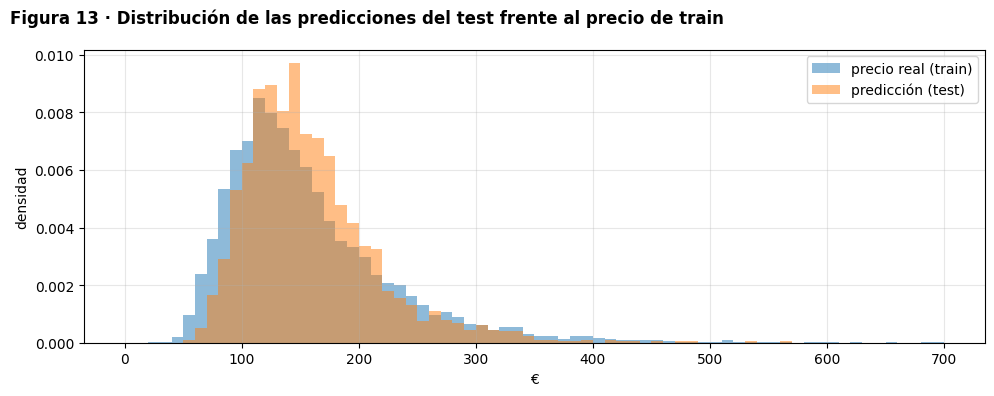

In [8]:
NOMBRE_FICHERO = 'submission_MatteoConcio.csv'   # cambiar por el nombre que corresponda

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    modelo_final = clone(FINAL).fit(XF, y)
pred = modelo_final.predict(XF_test)

sub = pd.DataFrame({'id': te['id'].to_numpy(), 'prediction': pred})

# Comprobaciones
assert list(sub.columns) == ['id', 'prediction']
assert len(sub) == len(te) == 2000
assert sub['id'].is_unique and set(sub['id']) == set(te['id'])
assert sub['prediction'].notna().all() and np.isfinite(sub['prediction']).all()
assert (sub['prediction'] > 0).all()

sub.to_csv(NOMBRE_FICHERO, index=False)
print(f'Guardado {NOMBRE_FICHERO}: {sub.shape[0]} filas, columnas {list(sub.columns)}')
print(sub.head().to_string(index=False))
print('\nPredicciones del test frente al precio de train:')
print(pd.DataFrame({'pred_test': sub.prediction.describe(), 'price_train': pd.Series(y).describe()}).round(2).to_string())

# Figura 13
f, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 700, 71)
ax.hist(y, bins=bins, density=True, alpha=.5, label='precio real (train)')
ax.hist(sub.prediction, bins=bins, density=True, alpha=.5, label='predicción (test)')
ax.set_xlabel('€'); ax.set_ylabel('densidad'); ax.legend(); ax.grid(alpha=.3)
f.suptitle('Figura 13 · Distribución de las predicciones del test frente al precio de train', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()